In [1]:
%pylab inline
import os
import numpy as np
import astropy.io.fits as pyfits
from astropy.table import Table
import catutil as utilities

import matplotlib as mpl
mpl.rcParams['savefig.dpi'] = 'figure'
mpl.rcParams['savefig.jpeg_quality'] = 98
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

import matplotlib.lines as mlines
titleList={ 'GAMA09H':'G09',
            'WIDE12H':'W12',
            'HECTOMAP':'HEC', 
            'VVDS':'VVD', 
            'GAMA15H':'G15', 
            'XMM':'XMM'}

Populating the interactive namespace from numpy and matplotlib


In [2]:
anaDir     =   './wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/'

nbin1       =   20
fwhm_bin    =   np.linspace(0.3,0.9,nbin1)
fwhm_bin_0  =   fwhm_bin[:-1]
fwhm_bin_1  =   fwhm_bin[1:]
gridPsf     =   (fwhm_bin_0+fwhm_bin_1)/2.
var_bin     =   np.linspace(0.001,0.01,nbin1)
var_bin_0   =   var_bin[:-1]
var_bin_1   =   var_bin[1:]
gridNoi     =   (var_bin_0+var_bin_1)/2.

disnames    =   ('gridNoi','histNoi','gridPsf','histPsf','num')

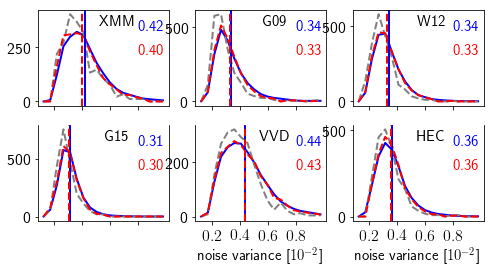

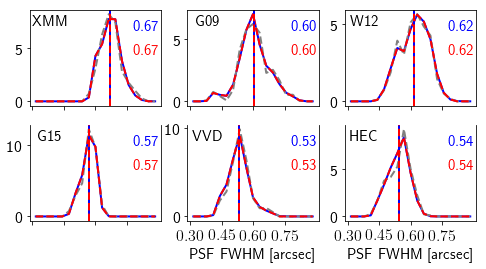

In [19]:
plt.close()
Dir='./wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_no_m/'
    
obsDis_var  =   np.zeros(nbin1-1)
obsDis_fwhm =   np.zeros(nbin1-1)
obsNum      =   np.zeros(nbin1-1)

simDis_var  =   np.zeros(nbin1-1)
simDis_fwhm =   np.zeros(nbin1-1)
simNum      =   np.zeros(nbin1-1)

simRDis_var =   np.zeros(nbin1-1)
simRDis_fwhm=   np.zeros(nbin1-1)
simRNum     =   np.zeros(nbin1-1)

figN=   plt.figure(figsize=(8,6))
figP=   plt.figure(figsize=(8,6))

for ii,fieldname in enumerate(utilities.field_names):
    anaFieldDir =   os.path.join(anaDir,'%s' %(fieldname))
    
    # observation
    obsOFname   =   os.path.join(anaFieldDir,'varPSF_dis_obs.csv')
    if os.path.isfile(obsOFname):
        t_dis_obs   =   Table.read(obsOFname)
    else:
        inFname =   os.path.join(Dir,'%s_no_m.fits' %(fieldname))
        data    =   pyfits.getdata(inFname)
        fwhms   =   utilities.get_psf_size(data)
        varNois =   utilities.get_noi_var(data)
        histNoi =   np.histogram(varNois,bins=var_bin,density=True)[0]
        histPsf =   np.histogram(fwhms,bins=fwhm_bin,density=True)[0]
        t_dis_obs=  Table(data=[gridNoi,histNoi,gridPsf,histPsf,len(data)*np.ones(len(gridNoi))],names=disnames)
        t_dis_obs.write(obsOFname)

    obsDis_var  +=  t_dis_obs['histNoi']*t_dis_obs['num']
    obsDis_fwhm +=  t_dis_obs['histPsf']*t_dis_obs['num']
    obsNum      +=  t_dis_obs['num']
    axN =   figN.add_subplot(3,3,ii+1)
    gg1 =   t_dis_obs['gridNoi']*100
    hh1 =   t_dis_obs['histNoi']
    axN.plot(gg1,hh1,'-',label='obs',c='b')
    
    # simulations
    for pend in ['sim','rw']:
        simOFname   =   os.path.join(anaFieldDir,'varPSF_dis_%s.csv' %pend)
        t_dis_sim   =   Table.read(simOFname)
    
        gg2 =   t_dis_sim['gridNoi']*100
        hh2 =   t_dis_sim['histNoi']
        dg  =   gg1[1]-gg1[0]
        if pend=='sim':
            cc='grey'
        else:
            cc='r'
        axN.plot(gg2,hh2,'--',label='sim',c=cc)
        
    ave1=   np.sum(gg1*hh1)*dg/100.
    ave2=   np.sum(gg2*hh2)*dg/100.
    axN.axvline(x=ave1,ls='-',c='blue')
    axN.axvline(x=ave2,ls='--',c='red')
    ymin,ymax=axN.get_ylim()
    axN.text(0.8,0.78*ymax, '%.2f' %ave1,
        color='blue',fontsize=15)
    axN.text(0.8,0.52*ymax, '%.2f' %ave2,
        color='red',fontsize=15)
    axN.set_xticks((0.2,0.4,0.6,0.8))
    axN.yaxis.set_major_formatter(ticker.FormatStrFormatter('%d'))
    if fieldname in ['VVDS', 'HECTOMAP']:
        axN.set_xlabel(r'noise variance~[$10^{-2}$]',fontsize=15)
    else:
        axN.set_xticklabels(())
        #axN.spines['bottom'].set_visible(False)
    axN.set_title(titleList[fieldname],y=1.0, pad=-15,x=0.6,fontsize=15)
    #axN.spines['right'].set_visible(False)
    if fieldname not in ['XMM', 'GAMA09H','WIDE12H']:
        axN.spines['top'].set_visible(False)

    axP =   figP.add_subplot(3,3,ii+1)
    gg1 =   t_dis_obs['gridPsf']
    hh1 =   t_dis_obs['histPsf']
    axP.plot(gg1,hh1,'-',label='obs',c='b')
    for pend in ['sim','rw']:
        simOFname   =   os.path.join(anaFieldDir,'varPSF_dis_%s.csv' %pend)
        t_dis_sim   =   Table.read(simOFname)
    
        gg2 =   t_dis_sim['gridPsf']
        hh2 =   t_dis_sim['histPsf']
        dg  =   gg1[1]-gg1[0]
        if pend=='sim':
            cc='grey'
            simDis_var +=  t_dis_sim['histNoi']*t_dis_sim['num']
            simDis_fwhm+=  t_dis_sim['histPsf']*t_dis_sim['num']
            simNum     +=  t_dis_sim['num']
        else:
            simRDis_var +=  t_dis_sim['histNoi']*t_dis_sim['num']
            simRDis_fwhm+=  t_dis_sim['histPsf']*t_dis_sim['num']
            simRNum     +=  t_dis_sim['num']
            cc='r'
        axP.plot(gg2,hh2,'--',label='sim',c=cc)
            
    ave1=   np.sum(gg1*hh1)*dg
    ave2=   np.sum(gg2*hh2)*dg
    axP.axvline(x=ave1,ls='-',c='blue')
    axP.axvline(x=ave2,ls='--',c='red')

    ymin,ymax=axP.get_ylim()
    axP.text(0.78,0.78*ymax, '%.2f' %ave1,
        color='blue',fontsize=15)
    axP.text(0.78,0.52*ymax, '%.2f' %ave2,
        color='red',fontsize=15)
    axP.set_xticks((0.3,0.45,0.6,0.75))
    axP.yaxis.set_major_formatter(ticker.FormatStrFormatter('%d'))
    if fieldname in ['VVDS', 'HECTOMAP']:
        axP.set_xlabel('PSF FWHM~[arcsec]',fontsize=15)
    else:
        axP.set_xticklabels(())
        #axP.spines['bottom'].set_visible(False)
    #axP.spines['right'].set_visible(False)
    if fieldname not in ['XMM', 'GAMA09H','WIDE12H']:
        axP.spines['top'].set_visible(False)

    axP.set_title(titleList[fieldname],y=1.0, pad=-15,x=0.15,fontsize=15)

In [20]:
obsDis_var /=obsNum
obsDis_fwhm/=obsNum

simRDis_var /=simRNum
simRDis_fwhm/=simRNum
simDis_var /=simNum
simDis_fwhm/=simNum

axN =   figN.add_subplot(3,3,7)
axN.plot(gridNoi*100,obsDis_var,'-',label='obs',c='b')
axN.plot(gridNoi*100,simRDis_var,'--',label='sim',c='r')
axN.plot(gridNoi*100,simDis_var,'--',label='sim',c='grey')
dg  =   (gridNoi[1]-gridNoi[0])*100.
ave1=   sum(gridNoi*obsDis_var)*dg
ave2=   sum(gridNoi*simRDis_var)*dg
axN.axvline(x=ave1,ls='-',c='blue')
axN.axvline(x=ave2,ls='--',c='red')
ymin,ymax=axN.get_ylim()
axN.text(0.8,0.78*ymax, '%.2f' %ave1,
    color='blue',fontsize=15)
axN.text(0.8,0.52*ymax, '%.2f' %ave2,
    color='red',fontsize=15)

axN.set_xticks((0.2,0.4,0.6,0.8))
axN.yaxis.set_major_formatter(ticker.FormatStrFormatter('%d'))
axN.set_xlabel(r'noise variance~[$10^{-2}$]',fontsize=15)
axN.set_title('All',y=1.0, pad=-15,x=0.6,fontsize=15)
#axN.spines['right'].set_visible(False)
axN.spines['top'].set_visible(False)

axN       = figN.add_subplot(3,3,8)
data_line = mlines.Line2D([], [], color='blue', ls='-', label='Observation')
sims_line = mlines.Line2D([], [], color='red', ls='-',label='Simulation')
axN.set_axis_off()
axN.legend(handles=[data_line,sims_line],loc='lower center')
#figN.tight_layout()

figN.subplots_adjust(left=0.05,
                bottom=0.12, 
                right=0.98, 
                top=0.92, 
                wspace=0.20, 
                hspace=0.01)

axP =   figP.add_subplot(3,3,7)
axP.plot(gridPsf,obsDis_fwhm,'-',label='obs',c='b')
axP.plot(gridPsf,simRDis_fwhm,'--',label='sim',c='r')
axP.plot(gridPsf,simDis_fwhm,'--',label='sim',c='grey')

dg  =gridPsf[1]-gridPsf[0]
ave1=sum(gridPsf*obsDis_fwhm)*dg
ave2=sum(gridPsf*simRDis_fwhm)*dg
axP.axvline(x=ave1,ls='-',c='blue')
axP.axvline(x=ave2,ls='--',c='red')
ymin,ymax=axP.get_ylim()
axP.text(0.78,0.78*ymax, '%.2f' %ave1,
    color='blue',fontsize=15)
axP.text(0.78,0.52*ymax, '%.2f' %ave2,
    color='red',fontsize=15)

axP.set_xticks((0.3,0.45,0.6,0.75))
axP.yaxis.set_major_formatter(ticker.FormatStrFormatter('%d'))
axP.set_xlabel('PSF FWHM~[arcsec]',fontsize=15)
axP.set_title('All',y=1.0, pad=-15,x=0.15,fontsize=15)
#axP.spines['right'].set_visible(False)
axP.spines['top'].set_visible(False)

axP       =   figP.add_subplot(3,3,8)
data_line = mlines.Line2D([], [], color='blue', ls='-', label='Observation')
sims_line = mlines.Line2D([], [], color='red', ls='-',label='Simulation')
axP.set_axis_off()
axP.legend(handles=[data_line,sims_line],loc='lower center')
#figP.tight_layout()
figP.subplots_adjust(left=0.05,
                bottom=0.12, 
                right=0.98, 
                top=0.92, 
                wspace=0.20, 
                hspace=0.01)

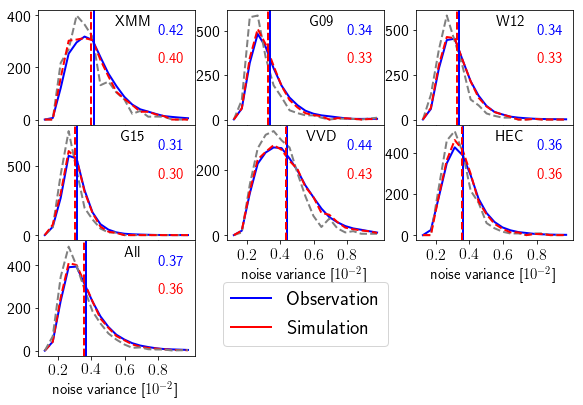

In [21]:
figN

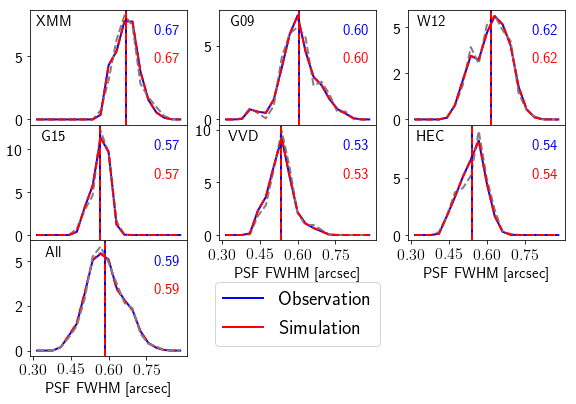

In [22]:
figP

In [23]:
pltDir  =   os.path.join(anaDir,'plot/psfNoi/')
figN.savefig(os.path.join(pltDir,'noiVar_reCheck_recut.eps'))
figP.savefig(os.path.join(pltDir,'psfFWHM_reCheck_recut.eps'))
figN.savefig(os.path.join(pltDir,'noiVar_reCheck_recut.png'))
figP.savefig(os.path.join(pltDir,'psfFWHM_reCheck_recut.png'))